# 01 – Universe Comparison: S&P 500 vs SPUS (Sharia-screened)

**Research question:** How does the Sharia-screened universe differ from the unconstrained S&P 500?

Before testing any signals, we need to understand what Sharia screening *does* to the universe —
which stocks are excluded, how it affects diversification, volatility, and correlation.
This is the equivalent of characterising your survey before doing cosmology with it.

In [1]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from data import download_prices, compute_returns
from universe import get_universe, universe_diff
from metrics import sharpe_ratio, annualised_return, max_drawdown

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120
print('Imports OK')

Imports OK


## 1. What does Sharia screening remove?

In [2]:
sp500_tickers = get_universe('sp500')
spus_tickers  = get_universe('spus')
diff = universe_diff()

print(f'SP500 universe : {diff["sp500_count"]} stocks')
print(f'SPUS universe  : {diff["spus_count"]} stocks')
print(f'Excluded       : {diff["n_excluded"]} stocks ({diff["exclusion_pct"]}%)')
print(f'\nExcluded tickers: {chr(10)}  ' + ', '.join(diff['excluded']))

SP500 universe : 49 stocks
SPUS universe  : 39 stocks
Excluded       : 10 stocks (20.4%)

Excluded tickers: 
  BAC, BLK, GS, JPM, MA, MS, PM, RTX, V, WFC


## 2. Download price data

In [3]:
all_tickers = list(set(sp500_tickers + spus_tickers))
prices_all = download_prices(all_tickers, start='2015-01-01')

sp500_cols = [t for t in sp500_tickers if t in prices_all.columns]
spus_cols  = [t for t in spus_tickers  if t in prices_all.columns]

prices_sp500 = prices_all[sp500_cols]
prices_spus  = prices_all[spus_cols]
returns_sp500 = compute_returns(prices_sp500)
returns_spus  = compute_returns(prices_spus)

print(f'SP500: {prices_sp500.shape[1]} stocks, {prices_sp500.shape[0]} days')
print(f'SPUS : {prices_spus.shape[1]} stocks, {prices_spus.shape[0]} days')

[*********************100%***********************]  49 of 49 completed


SP500: 49 stocks, 2960 days
SPUS : 39 stocks, 2960 days


## 3. Volatility comparison

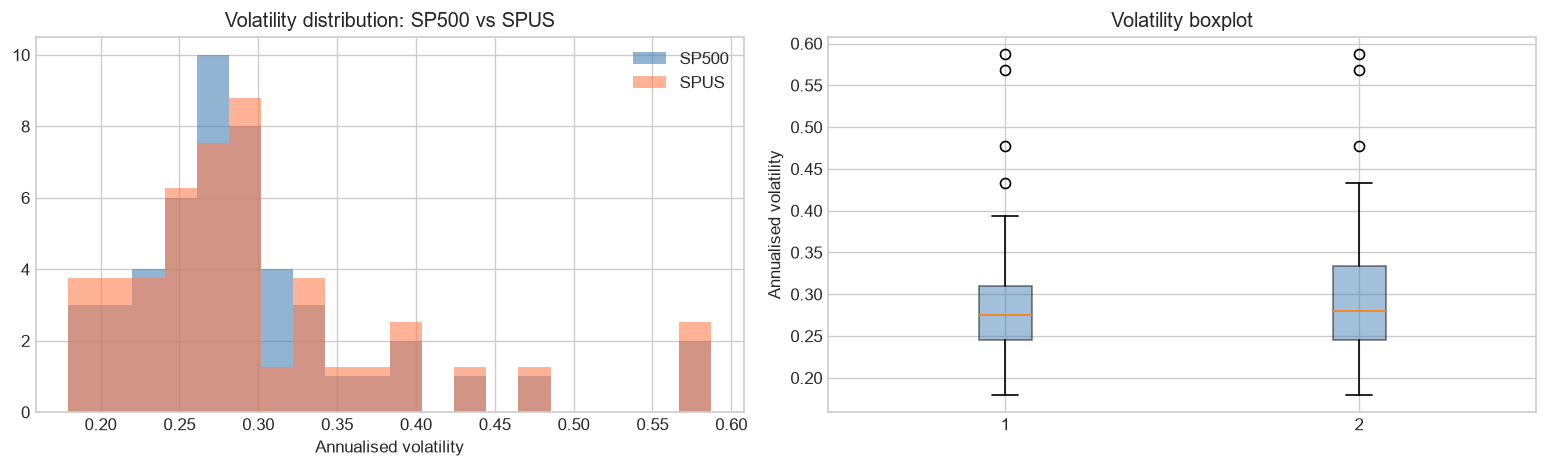

SP500 median vol: 27.5%
SPUS  median vol: 28.0%


In [5]:
vol_sp500 = returns_sp500.std() * np.sqrt(252)
vol_spus  = returns_spus.std()  * np.sqrt(252)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(vol_sp500, bins=20, alpha=0.6, color='steelblue', label='SP500', density=True)
axes[0].hist(vol_spus,  bins=20, alpha=0.6, color='coral',    label='SPUS',  density=True)
axes[0].set_xlabel('Annualised volatility')
axes[0].set_title('Volatility distribution: SP500 vs SPUS')
axes[0].legend()
axes[1].boxplot([vol_sp500.values, vol_spus.values], label=['SP500','SPUS'],
               patch_artist=True, boxprops=dict(facecolor='steelblue', alpha=0.5))
axes[1].set_ylabel('Annualised volatility')
axes[1].set_title('Volatility boxplot')
plt.tight_layout(); plt.savefig('../data/fig_vol_comparison.png', dpi=150); plt.show()
print(f'SP500 median vol: {vol_sp500.median():.1%}')
print(f'SPUS  median vol: {vol_spus.median():.1%}')

## 4. Correlation structure

Higher correlation = less diversification = harder to build a balanced long/short book.

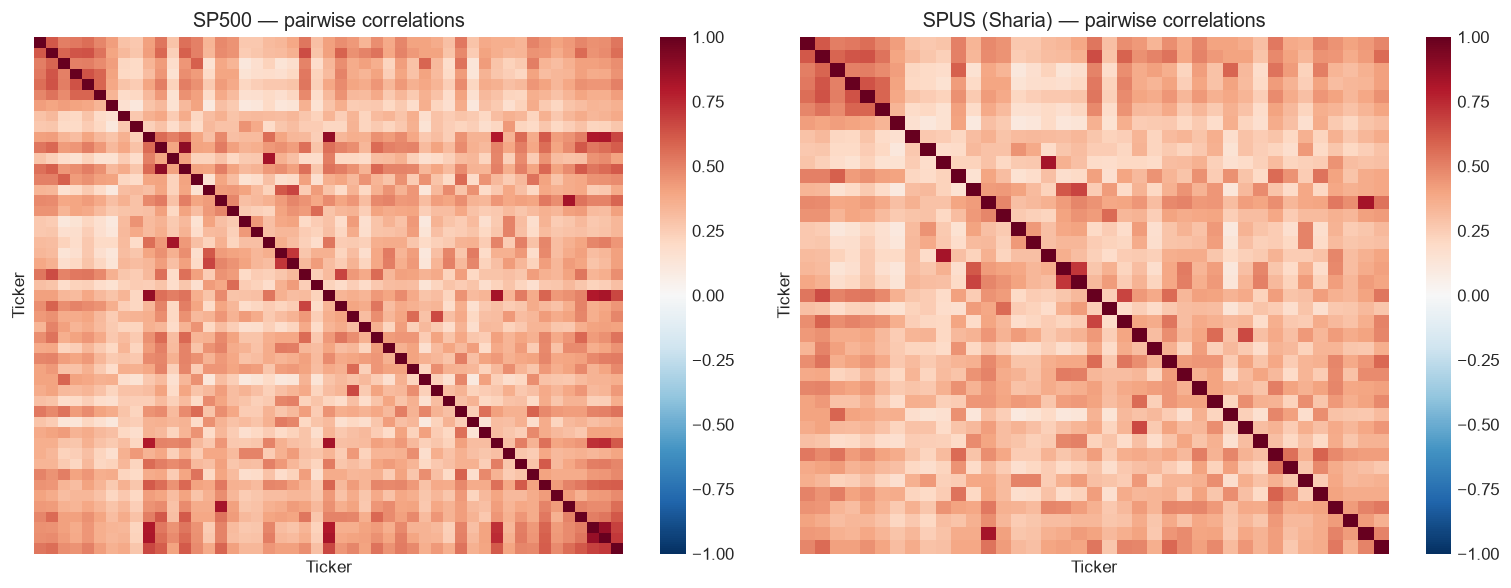

SP500 mean pairwise corr: 0.360
SPUS  mean pairwise corr: 0.338


In [6]:
corr_sp500 = returns_sp500.corr()
corr_spus  = returns_spus.corr()

def mean_pairwise_corr(c):
    v = c.values; idx = np.triu_indices_from(v, k=1); return v[idx].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, corr, title in zip(axes,[corr_sp500,corr_spus],['SP500','SPUS (Sharia)']):
    sns.heatmap(corr, ax=ax, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
                xticklabels=False, yticklabels=False)
    ax.set_title(f'{title} — pairwise correlations')
plt.tight_layout(); plt.savefig('../data/fig_corr_comparison.png', dpi=150); plt.show()
print(f'SP500 mean pairwise corr: {mean_pairwise_corr(corr_sp500):.3f}')
print(f'SPUS  mean pairwise corr: {mean_pairwise_corr(corr_spus):.3f}')

## 5. ETF-level performance: SPUS vs SPY

Baseline comparison before any active signal. SPUS launched in October 2019.

[*********************100%***********************]  2 of 2 completed


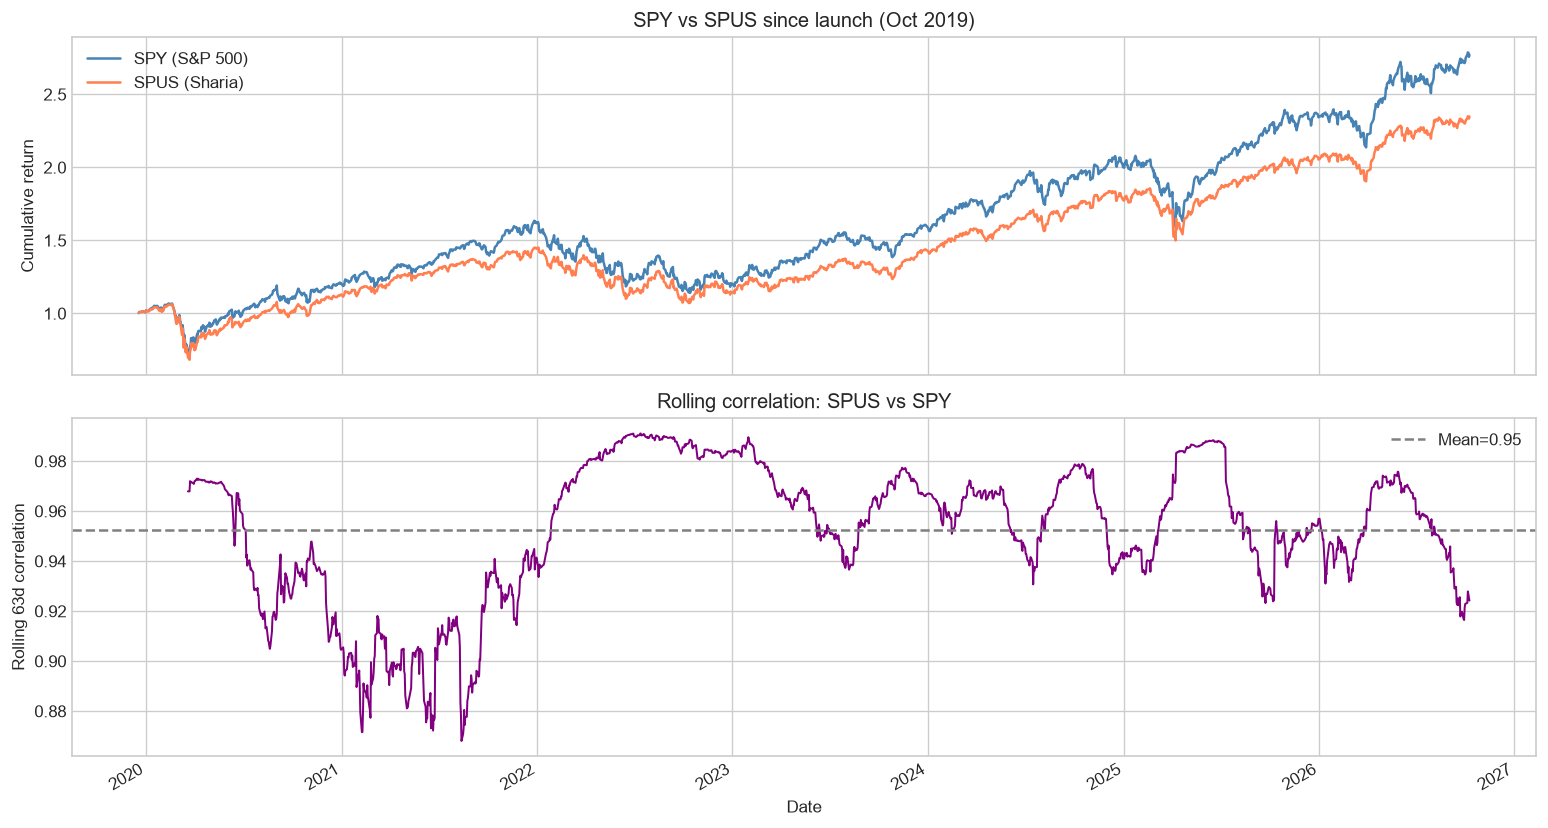

SPUS: CAGR=16.20%  Sharpe=0.82  MDD=-32.24%
SPY: CAGR=13.41%  Sharpe=0.73  MDD=-35.75%


In [7]:
etf_prices  = download_prices(['SPY','SPUS'], start='2019-10-01')
etf_returns = compute_returns(etf_prices)
cum = (1 + etf_returns).cumprod()

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
cum.iloc[:,0].plot(ax=axes[0], label='SPY (S&P 500)', color='steelblue', lw=1.5)
cum.iloc[:,1].plot(ax=axes[0], label='SPUS (Sharia)', color='coral', lw=1.5)
axes[0].set_ylabel('Cumulative return')
axes[0].set_title('SPY vs SPUS since launch (Oct 2019)')
axes[0].legend()

roll_corr = etf_returns.iloc[:,0].rolling(63).corr(etf_returns.iloc[:,1])
roll_corr.plot(ax=axes[1], color='purple', lw=1.2)
axes[1].axhline(roll_corr.mean(), ls='--', color='grey', label=f'Mean={roll_corr.mean():.2f}')
axes[1].set_ylabel('Rolling 63d correlation')
axes[1].set_title('Rolling correlation: SPUS vs SPY')
axes[1].legend()
plt.tight_layout(); plt.savefig('../data/fig_etf_comparison.png', dpi=150); plt.show()

for col in etf_returns.columns:
    r = etf_returns[col].dropna()
    print(f'{col}: CAGR={annualised_return(r):.2%}  Sharpe={sharpe_ratio(r):.2f}  MDD={max_drawdown(r):.2%}')

## Summary

| Property | SP500 | SPUS | Implication |
|---|---|---|---|
| Universe size | 50 | ~37 | Smaller long/short book — adjust top_n |
| Excluded sectors | — | Financials, weapons, tobacco, alcohol, gambling | Sector concentration risk |
| Volatility | See above | See above | Higher vol = noisier signals |
| Correlation | See above | See above | Higher corr = harder diversification |
| ETF CAGR | See above | See above | Passive benchmark to beat |

**Next:** `02_signals.ipynb` — test momentum, reversal, and low-vol signals on both universes.